### **Description**

This recipe shows how to calculate the heat content of the surface mixed layer using monthly-mean outputs from the National Oceanography Centre Near-Present-Day global eORCA1 configuration of NEMO forced using JRA55-do from 1976-2024.

For more details on this model configuration and the available outputs, users can explore the Near-Present-Day documentation [here](https://noc-msm.github.io/NOC_Near_Present_Day/).

---
### **Background**
The heat content of the ocean surface mixed layer is routinely used to characterise energy exchanges between the atmosphere and the upper ocean, and can be defined using the conservative temperature field at time $t$ as follows:

$$H_{_{MLD}}(\lambda, \phi, t) = c_p \int_{z=-h_{MLD}}^{\eta}  \rho(\lambda, \phi, z, t) \ \Theta (\lambda, \phi, z, t) \ dz$$

where $c_p$ is the specific heat capacity of seawater, $h_{MLD}(\lambda, \phi, t)$ is the spatially-varying mixed layer depth, $\eta$ is the sea surface, $\rho$ is the in-situ density and $\Theta$ is the conservative temperature.

For a Boussinesq ocean model, such as NEMO, the above equation can be simplified by replacing the in-situ density with the reference density $\rho_o$ and a constant ocean model heat capacity $c_p^o$ in place of $c_p$. 

---

In [1]:
# -- Import required packages -- #
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import xarray as xr

from nemo_cookbook import NEMODataTree

xr.set_options(display_style="text")

### **Using Dask**

**Optional: Connect Client to Dask Local Cluster to run analysis in parallel.**

Note that, although using Dask is not strictly necessary for this simple example using eORCA1, if we wanted to generalise this recipe to eORCA025 or eORCA12 outputs, using Dask would be essential to avoid unnecessary slow calculations using only a single process.

In [ ]:
# -- Initialise Dask Local Cluster -- #
import os

import dask
from dask.distributed import Client, LocalCluster

# Update temporary directory for Dask workers:
dask.config.set({'temporary_directory': f"{os.getcwd()}/dask_tmp",
                 'local_directory': f"{os.getcwd()}/dask_tmp"
                 })

# Create Local Cluster:
cluster = LocalCluster(n_workers=4, threads_per_worker=3, memory_limit='5GB')
client = Client(cluster)
client

### **Accessing NEMO Model Data**
**Let's begin by loading the grid variables for our eORCA1 NEMO model from the [JASMIN Object Store](https://help.jasmin.ac.uk/docs/short-term-project-storage/using-the-jasmin-object-store/)**. 

**Alternatively, you can replace the ``domain_filepath`` below with a file path to your domain_cfg.nc file and read this with xarray's ``open_dataset()`` function.**

In [2]:
# Define directory path to ancillary files:
domain_filepath = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/npd-eorca1-jra55v1/domain_cfg"

# Open eORCA1 NEMO model domain_cfg:
ds_domain = xr.open_zarr(store=domain_filepath, consolidated=True, chunks={})

ds_domain

<xarray.Dataset> Size: 709MB
Dimensions:       (y: 331, x: 360, nav_lev: 75)
Coordinates:
  * y             (y) int64 3kB 0 1 2 3 4 5 6 7 ... 324 325 326 327 328 329 330
  * x             (x) int64 3kB 0 1 2 3 4 5 6 7 ... 353 354 355 356 357 358 359
  * nav_lev       (nav_lev) int64 600B 0 1 2 3 4 5 6 7 ... 68 69 70 71 72 73 74
Data variables: (12/50)
    atlmsk        (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    bathy_metry   (y, x) float32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    bottom_level  (y, x) int32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1f           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1t           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    e1u           (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    ...            ...
    top_level     (y, x) int32 477kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    umask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
    umaskutil     (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    vmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
    vmaskutil     (y, x) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    wmask         (nav_lev, y, x) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
Attributes:
    CfgName:    UNKNOWN
    CfgIndex:   -999
    Iperio:     1
    Jperio:     0
    NFold:      1
    NFtype:     F
    VertCoord:  zps
    IsfCav:     0
    file_name:  mesh_mask.nc
    TimeStamp:  01/03/2025 22:19:49 -0000

**Next, we need to import the sea water conservative temperature and vertical grid scale factors stored at T-points in a single dataset.**

**Let us select the time period between 2020-2024.**

In [3]:
# Define directory path to model output files:
gridT_url = "https://noc-msm-o.s3-ext.jc.rl.ac.uk/npd-eorca1-jra55v1/T1m"

# Construct NEMO model T-grid dataset, including conservative temperature (degC):
ds_gridT = xr.open_zarr(gridT_url, consolidated=True)

# Select (2020-01 to 2024-01) time interval:
ds_gridT = ds_gridT.sel(time_counter=slice("2020-01", "2024-01"))

ds_gridT

<xarray.Dataset> Size: 40GB
Dimensions:                (time_counter: 49, y: 331, x: 360, deptht: 75,
                            axis_nbounds: 2)
Coordinates:
  * time_counter           (time_counter) datetime64[ns] 392B 2020-01-16T12:0...
    time_centered          (time_counter) datetime64[ns] 392B dask.array<chunksize=(1,), meta=np.ndarray>
    nav_lat                (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
    nav_lon                (y, x) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
  * deptht                 (deptht) float32 300B 0.5058 1.556 ... 5.902e+03
Dimensions without coordinates: y, x, axis_nbounds
Data variables: (12/74)
    berg_latent_heat_flux  (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    deptht_bounds          (deptht, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
    e3t                    (time_counter, deptht, y, x) float32 2GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    empmr                  (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    evs                    (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    ficeberg               (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    ...                     ...
    ttrd_qns_li            (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    vohfcisf               (time_counter, deptht, y, x) float32 2GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    vohflisf               (time_counter, deptht, y, x) float32 2GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    vowflisf               (time_counter, deptht, y, x) float32 2GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
    zos                    (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
    zossq                  (time_counter, y, x) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
Attributes:
    name:         OUTPUT/eORCA1_1m_grid_T
    description:  ocean T grid variables
    title:        ocean T grid variables
    Conventions:  CF-1.6
    timeStamp:    2024-Dec-09 10:18:50 GMT
    uuid:         d4f9020a-a621-4a95-81da-0b477f67ed38

### **Creating a NEMODataTree**

**Next, let's create a NEMODataTree to store our domain and T-grid variables for the eORCA1 model.**

In [4]:
# Define dictionary of grid datasets defining eORCA1 parent model domain with no child/grand-child nests:
datasets = {"parent": {"domain": ds_domain, "gridT": ds_gridT}}

# Initialise a new NEMODataTree whose parent domain is zonally periodic & north-folding on F-points:
nemo = NEMODataTree.from_datasets(datasets=datasets, iperio=True, nftype="F", read_mask=True)

nemo

<xarray.DataTree 'NEMO model'>
Group: /
│   Dimensions:               (time_counter: 49, axis_nbounds: 2)
│   Coordinates:
│     * time_counter          (time_counter) datetime64[ns] 392B 2020-01-16T12:00...
│       time_centered         (time_counter) datetime64[ns] 392B dask.array<chunksize=(1,), meta=np.ndarray>
│   Dimensions without coordinates: axis_nbounds
│   Data variables:
│       time_centered_bounds  (time_counter, axis_nbounds) datetime64[ns] 784B dask.array<chunksize=(1, 2), meta=np.ndarray>
│       time_counter_bounds   (time_counter, axis_nbounds) datetime64[ns] 784B dask.array<chunksize=(1, 2), meta=np.ndarray>
│   Attributes:
│       nftype:   F
│       iperio:   True
├── Group: /gridT
│       Dimensions:                (time_counter: 49, j: 331, i: 360, k: 75,
│                                   axis_nbounds: 2)
│       Coordinates:
│           time_centered          (time_counter) datetime64[ns] 392B dask.array<chunksize=(1,), meta=np.ndarray>
│         * j                      (j) int64 3kB 1 2 3 4 5 6 ... 326 327 328 329 330 331
│         * i                      (i) int64 3kB 1 2 3 4 5 6 ... 355 356 357 358 359 360
│           gphit                  (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           glamt                  (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│         * k                      (k) int64 600B 1 2 3 4 5 6 7 ... 69 70 71 72 73 74 75
│         * deptht                 (k) float64 600B 0.5058 1.556 ... 5.698e+03 5.902e+03
│       Dimensions without coordinates: axis_nbounds
│       Data variables: (12/78)
│           berg_latent_heat_flux  (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           deptht_bounds          (k, axis_nbounds) float32 600B dask.array<chunksize=(25, 2), meta=np.ndarray>
│           e3t                    (time_counter, k, j, i) float32 2GB dask.array<chunksize=(1, 25, 331, 360), meta=np.ndarray>
│           empmr                  (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           evs                    (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           ficeberg               (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           ...                     ...
│           zos                    (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           zossq                  (time_counter, j, i) float32 23MB dask.array<chunksize=(1, 331, 360), meta=np.ndarray>
│           tmask                  (k, j, i) int8 9MB dask.array<chunksize=(75, 331, 360), meta=np.ndarray>
│           tmaskutil              (j, i) int8 119kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           e1t                    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           e2t                    (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│       Attributes:
│           name:         OUTPUT/eORCA1_1m_grid_T
│           description:  ocean T grid variables
│           title:        ocean T grid variables
│           Conventions:  CF-1.6
│           timeStamp:    2024-Dec-09 10:18:50 GMT
│           uuid:         d4f9020a-a621-4a95-81da-0b477f67ed38
├── Group: /gridU
│       Dimensions:       (k: 75, j: 331, i: 360)
│       Coordinates:
│         * k             (k) int64 600B 1 2 3 4 5 6 7 8 9 ... 68 69 70 71 72 73 74 75
│         * depthu        (k) float64 600B 0.5058 1.556 2.668 ... 5.698e+03 5.902e+03
│         * j             (j) int64 3kB 1 2 3 4 5 6 7 8 ... 325 326 327 328 329 330 331
│         * i             (i) float64 3kB 1.5 2.5 3.5 4.5 ... 357.5 358.5 359.5 360.5
│           gphiu         (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=np.ndarray>
│           glamu         (j, i) float64 953kB dask.array<chunksize=(331, 360), meta=

### **Calculating Mixed Layer Heat Content**

**Now we have constructed our `NEMODataTree`, let's calculate the heat content of the mixed layer in the Atlantic Ocean.**

$$H_{_{MLD}}(t, j, i) = \rho_0 \, c_p^0 \ \sum_{k=1}^{N_k}
(\chi(t, k, j, i) \ . \ e_{1t}(j, i) \ . \ e_{2t}(j, i) \ . \ e_{3t}(t, k, j, i) \ . \ \Theta(t, k, j, i))$$

where $\chi \in [0, 1]$:

* $\chi = 1$ for cells entirely within the mixed layer.

* $\chi$ for cells partially contained within the mixed layer.

* $\chi = 0$ below.

In this example, our eORCA1 model uses $z^{*}$ vertical coordinates with time-evolving vertical grid scale factors, hence $e_{3t}(t, z, j, i)$ is a function of time and space.


Rather than estimating the mixed layer heat content by integrating over the `Nk` uppermost vertical levels, such that `deptht[Nk]` is closest to local mixed layer depth (i.e., $z_{MLD}(t, j, i)$), we can use the `.depth_integral()` method to perform vertical integration between two depth surfaces.

Here, we:

- Clip variables to a subpolar North Atlantic bounding box (40–60°N, 40–15°W). 
- Integrate with respect to depth (between 0 - $z_{MLD}$ m).

In [5]:
# Reference density [kg m-3]
rho0 = 1025
# Reference specific heat capacity [J kg-1 C-1]
cp0 = 3991.86

# Define geographical bounding box for 40–60°N, 40–15°W:
bbox = (-40, -15, 40, 60) 

# Conservative temperature in the SPNA [deg C]
thetao_con = nemo["gridT/thetao_con"].clip(bbox=bbox)

# Surface mixed layer depth in the SPNA [m]
z_mld = nemo["gridT/mlotst"].sel_like(thetao_con)

# Calculate mixed layer heat content [Joules] in the SPNA:
H_mld = rho0 * cp0 * thetao_con.depth_integral(limits=(0, z_mld))

H_mld

<NEMODataTree  'NEMO model' (Domain: '.', Grid: 'gridT', Grid Type: 'T')>

<xarray.DataArray 'integral_z(thetao_con)' (time_counter: 49, j: 29, i: 25)> Size: 284kB
dask.array<mul, shape=(49, 29, 25), dtype=float64, chunksize=(1, 29, 25), chunktype=numpy.ndarray>
Coordinates:
  * time_counter   (time_counter) datetime64[ns] 392B 2020-01-16T12:00:00 ......
    time_centered  (time_counter) datetime64[ns] 392B dask.array<chunksize=(1,), meta=np.ndarray>
  * j              (j) int64 232B 246 247 248 249 250 ... 270 271 272 273 274
  * i              (i) int64 200B 248 249 250 251 252 ... 268 269 270 271 272
    gphit          (j, i) float64 6kB 40.31 40.32 40.33 ... 59.56 59.51 59.46
    glamt          (j, i) float64 6kB -39.58 -38.58 -37.57 ... -14.95 -13.81
Attributes:
    standard_name:       cell_thickness
    long_name:           T-cell thickness
    units:               m
    online_operation:    average
    interval_operation:  3600 s
    interval_write:      1 month
    cell_methods:        time: mean (interval: 3600 s)

**Notice that the output above contains dask arrays, so we haven't actually computed the mixed layer heat content yet. To do this, we need to call the ``.compute()`` method:**

In [6]:
H_mld = H_mld.compute()

### **Visualising Subpolar North Atlantic Ocean Mixed Layer Heat Content**

**Next, let's visualise the mixed layer heat content in the subpolar North Atlantic region.**

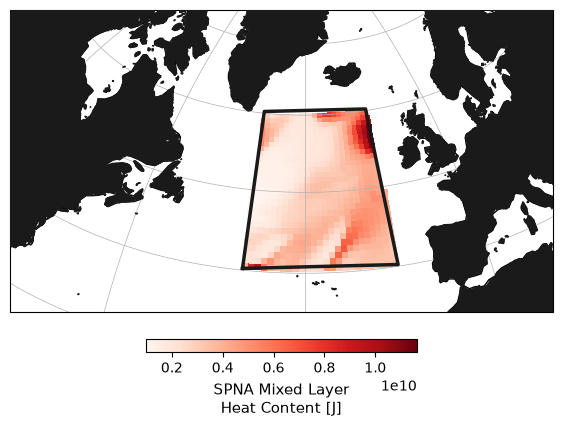

In [7]:
# -- Create a Figure with an orthographic (globe) projection -- #
proj = ccrs.Orthographic(central_longitude=-30, central_latitude=35)

# Plot example March mixed layer heat content:
(H_mld
 .isel(time_counter=2)
 .geoplot(cmap="Reds",
          projection=proj,
          extent=(-80, 10, 35, 70),
          figsize=(7, 7),
          clabel_kwargs={"fontsize": 11, "label": "SPNA Mixed Layer\nHeat Content [J]"},
          )
 )

# Plot bounding box for SPNA region:
plt.plot([-40, -15, -15, -40, -40], [40, 40, 60, 60, 40], color="0.1", linewidth=2.5, transform=ccrs.PlateCarree())

**Finally, let's plot a timeseries of the area-integrated mixed layer heat content in the subpolar North Atlantic region.**

Text(0, 0.5, 'Mixed Layer Heat Content (ZJ)')

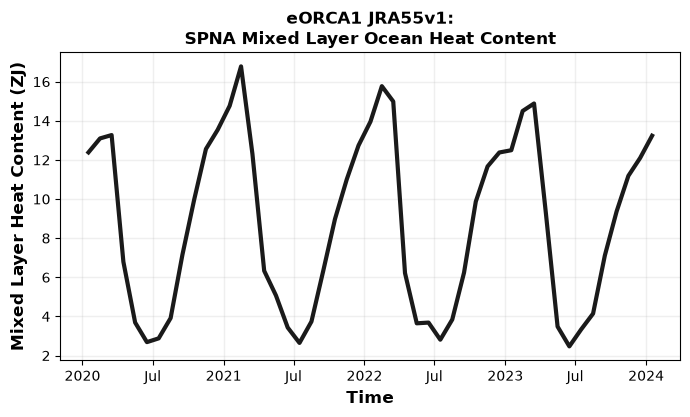

In [8]:
# -- Plotting mixed layer heat content time series for the SPNA -- #
plt.figure(figsize=(8, 4))
plt.grid(visible=True, lw=1, alpha=0.2)

(1E-21 * H_mld.integral(dims=["i", "j"])).plot(lw=3, color='0.1')

# Axes labels:
plt.title(label='eORCA1 JRA55v1:\nSPNA Mixed Layer Ocean Heat Content', fontdict={'size':12, 'weight':'bold'})
plt.xlabel(xlabel='Time', fontdict={'size':12, 'weight':'bold'})
plt.ylabel(ylabel='Mixed Layer Heat Content (ZJ)', fontdict={'size':12, 'weight':'bold'})